# Практическая работа № 4. Регрессионная модель

**Уровень:** B (данные заданы)
**Цель:** построить и интерпретировать модель линейной регрессии, сравнить несколько наборов признаков и корректно оценить качество.

**Данные:** `data/housing.csv`, целевая переменная — цена квартиры `price_kusd` в **тысячах долларов**. Предобработка — пайплайн из ПР-3 (вынесен в `src/preprocessing.py`).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sys.path.append("../src")
from preprocessing import clean_raw, build_preprocessor, NUM_COLS, CAT_COLS, TARGET

df = clean_raw(pd.read_csv("../data/housing.csv"))      # правила очистки без статистики (см. ПР-3)
X, y = df.drop(columns=TARGET), df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # то же разбиение, что в ПР-3
print("train:", X_train.shape, "| test:", X_test.shape)


def evaluate(model, X_tr, X_te, name):
    """Считает метрики на train и на test. MAE и RMSE — в тыс. $, R² — безразмерный."""
    res = {"модель": name}
    for part, Xp, yp in [("train", X_tr, y_train), ("test", X_te, y_test)]:
        pred = model.predict(Xp)
        res[f"MAE {part}"] = mean_absolute_error(yp, pred)
        res[f"RMSE {part}"] = np.sqrt(mean_squared_error(yp, pred))
        res[f"R² {part}"] = r2_score(yp, pred)
    return res

train: (800, 10) | test: (200, 10)


## 1. Базовая модель: все числовые признаки
Пайплайн: медианное заполнение → стандартизация → `LinearRegression`. Масштабирование нужно, чтобы коэффициенты были сравнимы между собой.

In [2]:
def numeric_pipe(cols):
    prep = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                                               ("sc", StandardScaler())]), cols)])
    return Pipeline([("prep", prep), ("model", LinearRegression())])

base = numeric_pipe(NUM_COLS).fit(X_train, y_train)
res_base = evaluate(base, X_train, X_test, "1. Все числовые (7 признаков)")
pd.DataFrame([res_base]).round(3).T

                                        0
модель      1. Все числовые (7 признаков)
MAE train                          12.608
RMSE train                         15.573
R² train                            0.762
MAE test                           13.569
RMSE test                          16.598
R² test                             0.758

In [3]:
coefs = pd.Series(base.named_steps["model"].coef_, index=NUM_COLS)
print("Коэффициенты базовой модели (признаки стандартизованы):")
coefs.round(2).sort_values()

Коэффициенты базовой модели (признаки стандартизованы):


dist_center_km   -11.56
area_m2           -5.27
rooms             -0.91
year_built         0.95
floor              1.65
living_area_m2     4.22
area_sqft         27.68
dtype: float64

**Интерпретация базовой модели.** MAE на test ≈ 13,6 тыс. $: в среднем модель ошибается на ≈ 13,6 тыс. $ при средней цене ≈ 95 тыс. $ (около 14%). RMSE ≈ 16,6 тыс. $ чуть больше MAE — это нормально, RMSE сильнее штрафует крупные промахи. R² на test ≈ 0,76: модель объясняет около 76% разброса цен; R² на train (0,762) почти такой же — переобучения нет.

Наибольший по модулю коэффициент у `area_sqft` (≈ +27,7). Но обратите внимание на `area_m2`: у неё коэффициент **отрицательный** (≈ −5,3), хотя больше площадь — дороже квартира. Это типичный симптом мультиколлинеарности: три признака описывают одну и ту же площадь, и модель «делит» её вклад между ними произвольным образом, иногда с обратным знаком. Коэффициенты такой модели нельзя интерпретировать по отдельности.

## 2. Мультиколлинеарность: корреляции и VIF
**VIF** (variance inflation factor) показывает, насколько признак «выражается» через остальные: VIF = 1 / (1 − R²ᵢ), где R²ᵢ — качество регрессии i-го признака на остальные. Принято считать, что VIF > 10 — серьёзная мультиколлинеарность. Считаем только по train.

In [4]:
def vif_table(X_df):
    imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X_df), columns=X_df.columns)
    rows = []
    for col in imp.columns:
        others = imp.drop(columns=col)
        r2 = LinearRegression().fit(others, imp[col]).score(others, imp[col])
        rows.append((col, 1 / (1 - r2) if r2 < 1 else np.inf))
    return pd.Series(dict(rows)).sort_values(ascending=False)

vif = vif_table(X_train[NUM_COLS])
print("VIF по всем числовым признакам:")
vif.round(1)

VIF по всем числовым признакам:


area_sqft         61.6
living_area_m2    33.3
area_m2           27.3
rooms              3.7
dist_center_km     1.0
floor              1.0
year_built         1.0
dtype: float64

In [5]:
# Итеративно убираем признак с наибольшим VIF, пока все VIF не станут < 10
kept = list(NUM_COLS)
while True:
    v = vif_table(X_train[kept])
    if v.max() < 10:
        break
    worst = v.idxmax()
    print(f"убираем {worst} (VIF = {v.max():.1f})")
    kept.remove(worst)
print("\nОставшиеся признаки:", kept)
vif_table(X_train[kept]).round(2)

убираем area_sqft (VIF = 61.6)
убираем area_m2 (VIF = 16.1)

Оставшиеся признаки: ['living_area_m2', 'rooms', 'floor', 'year_built', 'dist_center_km']


living_area_m2    3.40
rooms             3.39
floor             1.01
dist_center_km    1.00
year_built        1.00
dtype: float64

**Вывод по VIF.** До очистки VIF у `area_sqft` ≈ 62, у `living_area_m2` ≈ 33, у `area_m2` ≈ 27 — всё намного выше порога 10: три признака практически дублируют друг друга. Остальные признаки независимы (VIF ≈ 1). Алгоритм последовательно убрал `area_sqft` и `area_m2` и оставил `living_area_m2` и `rooms` (VIF ≈ 3,4 — допустимо). Выбор из трёх «эквивалентных» признаков не единственно возможный: `living_area_m2` оставлен потому, что в нём нет пропусков, а в `area_m2` их 3% плюс убранные опечатки.

## 3. Модель на сокращённом наборе числовых признаков

In [6]:
reduced = numeric_pipe(kept).fit(X_train, y_train)
res_red = evaluate(reduced, X_train, X_test, f"2. Сокращённый набор ({len(kept)} признаков)")

# Модель 3: сокращённые числовые + категориальные признаки, пайплайн из ПР-3
full = Pipeline([("prep", build_preprocessor(kept, CAT_COLS)), ("model", LinearRegression())]).fit(X_train, y_train)
res_full = evaluate(full, X_train, X_test, "3. Сокращённые числовые + категориальные")

results = pd.DataFrame([res_base, res_red, res_full]).set_index("модель").round(3)
results

                                          MAE train  RMSE train  R² train  MAE test  RMSE test  R² test
модель                                                                                                 
1. Все числовые (7 признаков)                12.608      15.573     0.762    13.569     16.598    0.758
2. Сокращённый набор (5 признаков)           13.031      16.050     0.747    14.123     17.682    0.726
3. Сокращённые числовые + категориальные      9.142      11.674     0.866    10.241     12.735    0.858

In [7]:
print("Коэффициенты сокращённой модели (стандартизованные признаки):")
pd.Series(reduced.named_steps["model"].coef_, index=kept).round(2).sort_values()

Коэффициенты сокращённой модели (стандартизованные признаки):


dist_center_km   -11.65
year_built         1.06
rooms              1.12
floor              1.74
living_area_m2    24.69
dtype: float64

**Сравнение трёх наборов признаков (метрики на test; MAE и RMSE — в тыс. $):**

| Модель | MAE | RMSE | R² |
|---|---|---|---|
| 1. Все 7 числовых | 13,6 | 16,6 | 0,758 |
| 2. Сокращённые 5 числовых | 14,1 | 17,7 | 0,726 |
| 3. Сокращённые числовые + категориальные | **10,2** | **12,7** | **0,858** |

1. **Удаление коллинеарных признаков чуть ухудшило качество** (R² 0,758 → 0,726), а не улучшило. Причина: три признака площади — это три *зашумлённых измерения* одной и той же величины, и вместе они дают более точную оценку площади, чем один. Для предсказания мультиколлинеарность не вредна, она вредит *интерпретации*: после удаления все коэффициенты стали осмысленными (площадь ≈ +24,7 — главный положительный фактор, расстояние до центра ≈ −11,7 — чем дальше, тем дешевле).
2. **Самый большой выигрыш даёт добавление категориальных признаков** (`district`, `condition`, `balcony`): MAE упал с 14,1 до 10,2 тыс. $, R² вырос до 0,858. Район и состояние квартиры объясняют заметную часть цены, которую числовые признаки не видят.
3. Разница между train и test небольшая у всех моделей (например, у модели 3 R² 0,866 и 0,858) — переобучения нет.

## 4. Графики: предсказание против истинного значения и остатки
Графики строятся для лучшей модели на **тестовой** выборке.

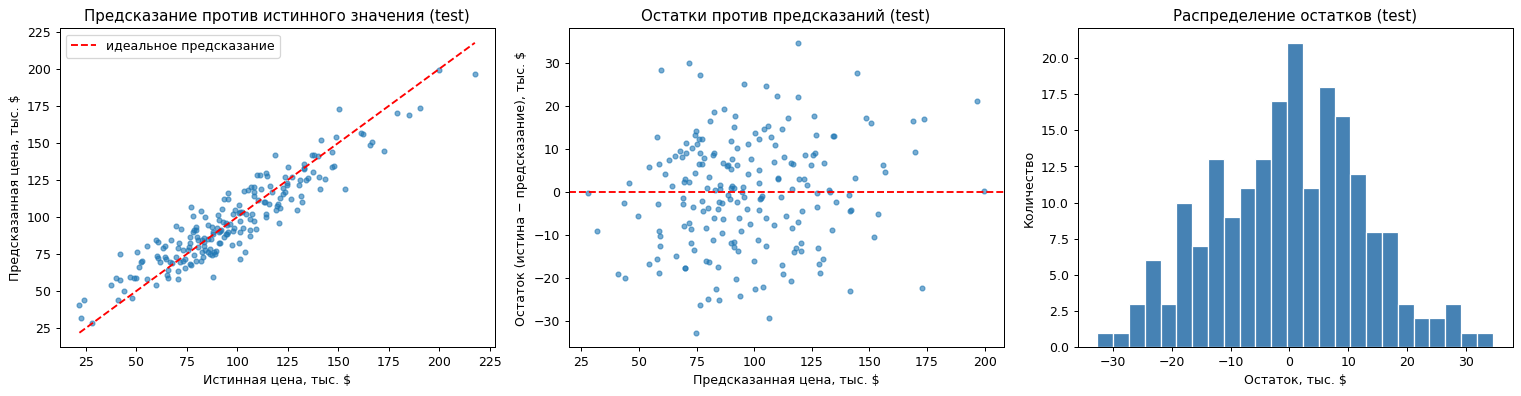

In [8]:
pred = full.predict(X_test)
resid = y_test - pred

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(y_test, pred, s=15, alpha=.6)
lim = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0].plot(lim, lim, "r--", label="идеальное предсказание")
axes[0].set_title("Предсказание против истинного значения (test)")
axes[0].set_xlabel("Истинная цена, тыс. $")
axes[0].set_ylabel("Предсказанная цена, тыс. $")
axes[0].legend()

axes[1].scatter(pred, resid, s=15, alpha=.6)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_title("Остатки против предсказаний (test)")
axes[1].set_xlabel("Предсказанная цена, тыс. $")
axes[1].set_ylabel("Остаток (истина − предсказание), тыс. $")

axes[2].hist(resid, bins=25, color="steelblue", edgecolor="white")
axes[2].set_title("Распределение остатков (test)")
axes[2].set_xlabel("Остаток, тыс. $")
axes[2].set_ylabel("Количество")
plt.tight_layout()
plt.show()

Средний остаток:   полная модель = -0.13 | числовая = -0.68
Остатки по районам (числовая модель), средний остаток:
district
Восток       -2.4
Север        -5.6
Центр         8.6
Юг           -1.0
неизвестно   -2.3
Name: price_kusd, dtype: float64


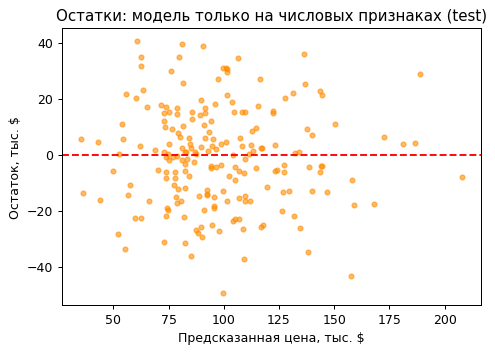

In [9]:
# Тот же график остатков для модели только на числовых признаках — для сравнения
resid_red = y_test - reduced.predict(X_test)
plt.figure(figsize=(6, 4))
plt.scatter(reduced.predict(X_test), resid_red, s=15, alpha=.6, color="darkorange")
plt.axhline(0, color="r", linestyle="--")
plt.title("Остатки: модель только на числовых признаках (test)")
plt.xlabel("Предсказанная цена, тыс. $")
plt.ylabel("Остаток, тыс. $")
plt.show()
print("Средний остаток:   полная модель =", round(resid.mean(), 2), "| числовая =", round(resid_red.mean(), 2))
print("Остатки по районам (числовая модель), средний остаток:")
print(resid_red.groupby(X_test["district"].fillna("неизвестно")).mean().round(1))

**Анализ остатков.**
- *Предсказание против истины (слева):* точки лежат вдоль красной диагонали — модель 3 в целом хорошо воспроизводит цену. Для самых дорогих квартир (> 170 тыс. $) модель слегка занижает цену (точки ниже диагонали).
- *Остатки против предсказаний (в центре):* остатки хаотично расположены вокруг нуля, без «воронки» и без изогнутого паттерна; их среднее ≈ −0,1 тыс. $. Распределение остатков (справа) близко к колоколообразному. Допущения линейной модели для модели 3 выполняются достаточно хорошо.
- *Для сравнения, модель только на числовых признаках:* средний остаток по районам **не равен нулю**: в «Центре» остаток ≈ +8,6 тыс. $ (модель занижает цену), в «Севере» ≈ −5,6 (завышает). Это систематический паттерн — признак того, что в модели не хватает важной информации (район). Добавление категориальных признаков его устранило.

## 5. Итоговый вывод о финальном наборе признаков

- **Финальная модель — №3:** числовые признаки `living_area_m2`, `rooms`, `floor`, `year_built`, `dist_center_km` + категориальные `district`, `condition`, `balcony`, предобработка пайплайном из ПР-3.
- Качество на тестовой выборке: **MAE ≈ 10,2 тыс. $** (модель ошибается в среднем примерно на 10 тысяч долларов, ≈ 11% от средней цены), **RMSE ≈ 12,7 тыс. $**, **R² ≈ 0,86**.
- Мультиколлинеарность устранена по VIF (три признака площади сведены к одному): это не повысило точность, но сделало коэффициенты интерпретируемыми.
- Остаток ошибки в основном объясняется шумом, которого в данных нет возможности «выучить» (в синтетических данных он задан случайно), а также нелинейными эффектами. Попробовать их поймать можно ансамблями деревьев — в ПР-7.
- *Оговорки:* коэффициенты показывают связь признаков с ценой в этих данных, но не доказывают причинность; коэффициенты стандартизованных признаков измеряются в «тыс. $ на 1 стандартное отклонение признака».